# 03 — Lead-lag antarprovinsi (Q7)

**Pertanyaan:** apakah kenaikan harga di satu provinsi diikuti provinsi lain beberapa hari
kemudian?

**Keputusan terkait:** kalau ada provinsi yang harganya selalu bergerak lebih dulu, tim procurement
bisa memakainya sebagai **peringatan dini** untuk outlet di provinsi lain.

**Data:** harga harian pasar tradisional 2018–2026 untuk 5 varian yang paling bergejolak atau
penting untuk menu: cabai merah keriting, cabai rawit merah, bawang merah, daging ayam, telur.

**Metode:**
1. **Skor lead per provinsi:** korelasi perubahan harga provinsi minggu lalu dengan perubahan
   harga provinsi lain minggu ini, dikurangi arah sebaliknya. Positif = provinsi ini bergerak
   lebih dulu.
2. **Uji Granger** dengan pemimpin yang ditentukan di awal (bukan dipilih dari data):
   rata-rata **Jawa Barat, Jawa Tengah, dan Jawa Timur**, tiga sentra produksi terbesar.
   Diuji ke setiap provinsi luar Jawa, dua arah.
3. **Profil lag harian:** berapa hari jeda antara Jawa dan luar Jawa.
4. **Pass-through:** kalau harga di Jawa naik 10% minggu ini, berapa kenaikan di provinsi lain
   minggu depan?

Perubahan harga dihitung sebagai log-return mingguan dari rata-rata harga harian (minggu
berakhir Jumat). Data mingguan dipakai supaya hari libur dan data yang tidak diperbarui setiap
hari tidak mengganggu.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import grangercausalitytests

from src.db import query
from src.viz import CMAP_DIV, INK_2, MUTED, SERIES, save, set_style, subtitle

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)

VARIAN = ["Cabai Merah Keriting", "Cabai Rawit Merah", "Bawang Merah Ukuran Sedang",
          "Daging Ayam Ras Segar", "Telur Ayam Ras Segar"]
PENDEK = {"Cabai Merah Keriting": "Cabai merah keriting", "Cabai Rawit Merah": "Cabai rawit merah",
          "Bawang Merah Ukuran Sedang": "Bawang merah", "Daging Ayam Ras Segar": "Daging ayam",
          "Telur Ayam Ras Segar": "Telur"}
SENTRA_JAWA = ["Jawa Barat", "Jawa Tengah", "Jawa Timur"]

In [2]:
df = query("""
    SELECT f.tanggal, w.nama_wilayah, w.pulau, k.nama_varian, f.harga
    FROM mart.fact_harga_harian AS f
    JOIN mart.dim_wilayah AS w USING (wilayah_id)
    JOIN mart.dim_komoditas AS k USING (komoditas_id)
    WHERE f.jenis_pasar_id = 1 AND NOT w.is_nasional AND k.nama_varian = ANY(:varian)
""", varian=VARIAN)
df["tanggal"] = pd.to_datetime(df["tanggal"])
pulau = df.drop_duplicates("nama_wilayah").set_index("nama_wilayah").pulau
LUAR_JAWA = sorted(pulau[pulau != "Jawa"].index)

harian = {v: g.pivot(index="tanggal", columns="nama_wilayah", values="harga") for v, g in df.groupby("nama_varian")}
mingguan = {v: np.log(h.resample("W-FRI").mean()).diff().iloc[1:] for v, h in harian.items()}
print(f"{len(df):,} harga harian; {len(LUAR_JAWA)} provinsi luar Jawa; "
      f"{len(mingguan[VARIAN[0]])} minggu")

371,798 harga harian; 28 provinsi luar Jawa; 460 minggu


## 1. Skor lead per provinsi

`lead` = korelasi(perubahan provinsi minggu lalu, perubahan rata-rata provinsi lain minggu ini)
`lag`  = korelasi(perubahan rata-rata provinsi lain minggu lalu, perubahan provinsi minggu ini)
`skor` = lead − lag

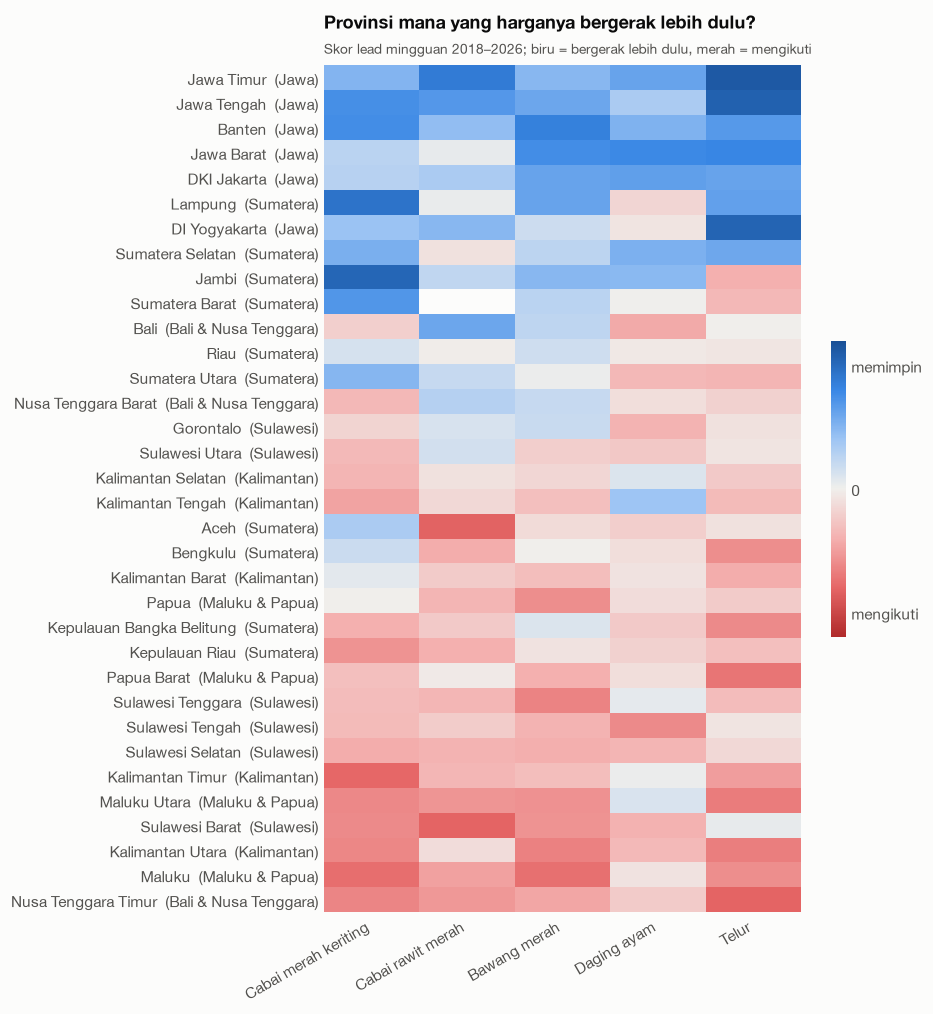

In [3]:
def skor_lead(r):
    hasil = {}
    for p in r.columns:
        lain = r.drop(columns=p).mean(axis=1)
        hasil[p] = r[p].shift(1).corr(lain) - lain.shift(1).corr(r[p])
    return pd.Series(hasil)


skor = pd.DataFrame({PENDEK[v]: skor_lead(mingguan[v]) for v in VARIAN})
skor = skor.loc[skor.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(skor, cmap=CMAP_DIV.reversed(), vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(skor.shape[1]), skor.columns, rotation=30, ha="right")
ax.set_yticks(range(skor.shape[0]), [f"{p}  ({pulau[p]})" for p in skor.index])
ax.grid(False)
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.35, ticks=[-0.5, 0, 0.5])
cb.ax.set_yticklabels(["mengikuti", "0", "memimpin"])
cb.outline.set_visible(False)
ax.set_title("Provinsi mana yang harganya bergerak lebih dulu?", pad=24)
subtitle(ax, "Skor lead mingguan 2018–2026; biru = bergerak lebih dulu, merah = mengikuti")
save(fig, "03_skor_lead_provinsi")
plt.show()

In [4]:
ringkas = skor.assign(rata_rata=skor.mean(axis=1), pulau=pulau[skor.index])
print("Rata-rata skor per kelompok pulau:")
display(ringkas.groupby("pulau").rata_rata.mean().sort_values(ascending=False).to_frame())
pd.concat([ringkas.head(6), ringkas.tail(6)])

Rata-rata skor per kelompok pulau:


,rata_rata
pulau,
Jawa,0.290
Sumatera,0.018
Bali & Nusa Tenggara,-0.088
Sulawesi,-0.139
Kalimantan,-0.139
Maluku & Papua,-0.195


,Cabai merah keriting,Cabai rawit merah,Bawang merah,Daging ayam,Telur,rata_rata,pulau
Jawa Timur,0.250,0.438,0.242,0.308,0.562,0.360,Jawa
Jawa Tengah,0.370,0.342,0.298,0.168,0.533,0.342,Jawa
Banten,0.379,0.223,0.418,0.258,0.339,0.323,Jawa
Jawa Barat,0.127,0.019,0.379,0.394,0.401,0.264,Jawa
DKI Jakarta,0.138,0.166,0.307,0.322,0.308,0.248,Jawa
Lampung,0.467,0.014,0.309,-0.082,0.314,0.205,Sumatera
Kalimantan Timur,-0.396,-0.181,-0.156,0.010,-0.249,-0.195,Kalimantan
Maluku Utara,-0.308,-0.276,-0.283,0.055,-0.342,-0.231,Maluku & Papua
Sulawesi Barat,-0.301,-0.407,-0.278,-0.192,0.019,-0.232,Sulawesi
Kalimantan Utara,-0.312,-0.060,-0.327,-0.170,-0.335,-0.241,Kalimantan


**Apakah pola ini stabil?** Skor dihitung ulang untuk dua periode terpisah (2018–2021 dan
2022–2026), lalu dikorelasikan antarprovinsi.

In [5]:
stabil = {}
for v in VARIAN:
    r = mingguan[v]
    a, b = skor_lead(r.loc[:"2021"]), skor_lead(r.loc["2022":])
    stabil[PENDEK[v]] = a.corr(b)
pd.Series(stabil, name="korelasi skor 2018–2021 vs 2022–2026").to_frame()

,korelasi skor 2018–2021 vs 2022–2026
Cabai merah keriting,0.853
Cabai rawit merah,0.890
Bawang merah,0.953
Daging ayam,0.669
Telur,0.823


**Insight:**
- **Jawa bergerak lebih dulu** (rata-rata skor +0,29). Sumatera netral (+0,02). Bali & Nusa
  Tenggara, Sulawesi, Kalimantan, serta Maluku & Papua **mengikuti** (−0,09 s.d. −0,20).
- Pemimpin terkuat berbeda per komoditas. Jawa Timur memimpin untuk cabai rawit merah dan
  telur; Banten, Jawa Barat, dan Jawa Tengah untuk bawang merah dan ayam. Untuk cabai merah
  keriting, **Lampung, Jambi, dan Sumatera Barat** juga memimpin, karena Sumatera juga sentra cabai merah.
- Pengikut paling jelas: NTT, Maluku, Kalimantan Utara, Sulawesi Barat, Maluku Utara.
- Polanya **stabil**: skor 2018–2021 dan 2022–2026 berkorelasi 0,67–0,95.

## 2. Uji Granger: Jawa → luar Jawa

Pemimpin = rata-rata perubahan harga Jawa Barat, Jawa Tengah, dan Jawa Timur. Untuk setiap
provinsi luar Jawa, diuji dua arah dengan lag 1–2 minggu. P-value terkecil dari dua lag dikali 2
(Bonferroni), lalu dikoreksi Holm untuk 28 provinsi.

In [6]:
def granger_p(r, sumber, target):
    x = pd.concat([target, sumber], axis=1).dropna()
    hasil = grangercausalitytests(x, maxlag=2)
    return min(1.0, 2 * min(hasil[lag][0]["ssr_ftest"][1] for lag in (1, 2)))


rows = []
for v in VARIAN:
    r = mingguan[v]
    jawa = r[SENTRA_JAWA].mean(axis=1)
    target = [p for p in LUAR_JAWA if p in r.columns]   # tidak semua provinsi melaporkan semua varian
    maju = [granger_p(r, jawa, r[p]) for p in target]
    mundur = [granger_p(r, r[p], jawa) for p in target]
    rows.append({
        "varian": PENDEK[v],
        "jawa_ke_luar_jawa": multipletests(maju, method="holm")[0].sum(),
        "luar_jawa_ke_jawa": multipletests(mundur, method="holm")[0].sum(),
        "n_provinsi": len(target),
    })
granger = pd.DataFrame(rows).set_index("varian")
granger

,jawa_ke_luar_jawa,luar_jawa_ke_jawa,n_provinsi
varian,,,
Cabai merah keriting,18,13,28
Cabai rawit merah,26,2,27
Bawang merah,28,6,28
Daging ayam,23,0,28
Telur,28,13,28


**Insight:**
- Perubahan harga di sentra Jawa **memprediksi harga minggu berikutnya** di 23–28 dari 28 provinsi
  luar Jawa untuk cabai rawit, bawang merah, daging ayam, dan telur.
- Arah sebaliknya jauh lebih jarang untuk cabai rawit (2 provinsi), bawang merah (6), dan
  daging ayam (0). Jadi hubungannya memang searah, dari Jawa ke luar Jawa.
- Untuk telur (28 vs 13) dan cabai merah keriting (18 vs 13), hubungannya lebih timbal balik.
  Untuk cabai merah keriting, ini karena sentranya tidak hanya di Jawa.

## 3. Berapa hari jedanya?

Korelasi perubahan harga harian Jawa (hari t − k) dengan rata-rata luar Jawa (hari t), untuk
k = 0–10 hari data. Garis kedua menunjukkan arah sebaliknya.

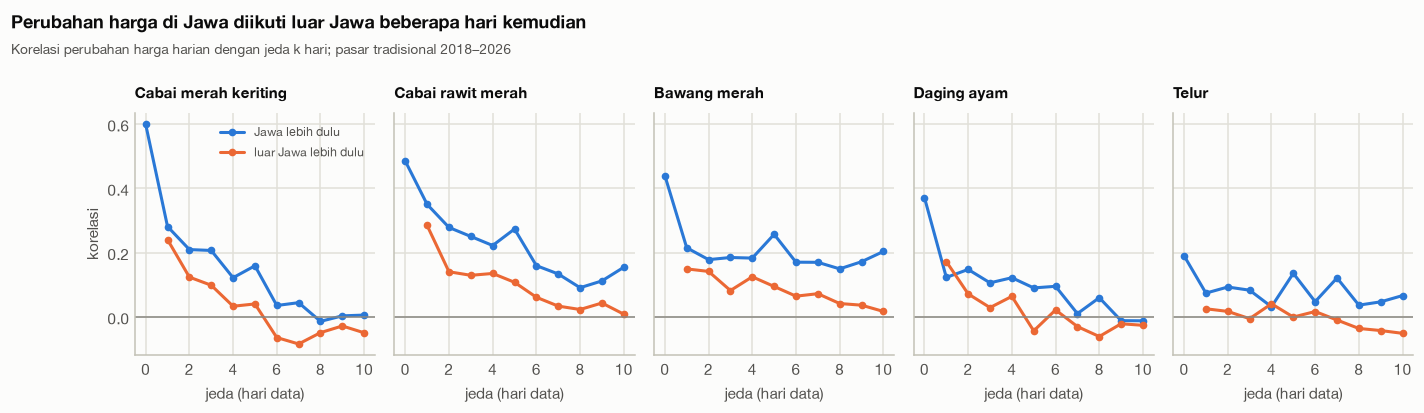

In [7]:
K = np.arange(0, 11)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
profil = {}
for ax, v in zip(axes, VARIAN):
    h = harian[v].dropna(how="all")
    r = np.log(h).diff()
    jawa, luar = r[SENTRA_JAWA].mean(axis=1), r[r.columns.intersection(LUAR_JAWA)].mean(axis=1)
    maju = [jawa.shift(k).corr(luar) for k in K]
    mundur = [np.nan] + [luar.shift(k).corr(jawa) for k in K[1:]]
    profil[PENDEK[v]] = pd.Series(maju, index=K)
    ax.plot(K, maju, "-o", color=SERIES[0], markersize=4, label="Jawa lebih dulu")
    ax.plot(K, mundur, "-o", color=SERIES[1], markersize=4, label="luar Jawa lebih dulu")
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_title(PENDEK[v], fontsize=10)
    ax.set_xticks([0, 2, 4, 6, 8, 10])
    ax.set_xlabel("jeda (hari data)")
axes[0].set_ylabel("korelasi")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Perubahan harga di Jawa diikuti luar Jawa beberapa hari kemudian", x=0.05, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.05, 0.87, "Korelasi perubahan harga harian dengan jeda k hari; pasar tradisional 2018–2026",
         color=INK_2, fontsize=9)
fig.subplots_adjust(top=0.72, wspace=0.08)
save(fig, "03_profil_jeda_harian")
plt.show()

In [8]:
jeda = pd.DataFrame(profil).T
jeda["korelasi_rata_k1_k5"] = jeda[[1, 2, 3, 4, 5]].mean(axis=1)
jeda["jeda_terakhir_di_atas_0.1"] = jeda[list(range(1, 11))].apply(
    lambda s: s[s > 0.1].index.max() if (s > 0.1).any() else 0, axis=1)
jeda[[0, 1, 2, 3, 5, 10, "korelasi_rata_k1_k5", "jeda_terakhir_di_atas_0.1"]]

,0,1,2,3,5,10,korelasi_rata_k1_k5,jeda_terakhir_di_atas_0.1
Cabai merah keriting,0.599,0.282,0.210,0.207,0.159,0.006,0.196,5
Cabai rawit merah,0.485,0.350,0.279,0.251,0.274,0.155,0.275,10
Bawang merah,0.440,0.215,0.178,0.185,0.257,0.204,0.204,10
Daging ayam,0.371,0.123,0.148,0.106,0.090,-0.012,0.118,4
Telur,0.191,0.074,0.093,0.083,0.136,0.067,0.084,7


**Insight:**
- Sebagian besar penyesuaian terjadi di **hari yang sama** (korelasi 0,19–0,60). Pasarnya
  cukup terhubung.
- Tetapi sisanya terus mengalir selama beberapa hari. Korelasi arah Jawa → luar Jawa tetap
  lebih tinggi dari arah sebaliknya sampai **~5 hari** untuk cabai merah keriting dan ayam, dan
  sampai **10 hari** untuk cabai rawit dan bawang merah.
- Jadi peringatan dini yang realistis adalah **1–2 minggu**, bukan berbulan-bulan.

## 4. Pass-through: berapa yang diteruskan ke minggu depan?

Untuk setiap provinsi luar Jawa: regresi perubahan harga minggu ini terhadap perubahan harga Jawa
minggu lalu, dengan perubahan harga provinsi itu sendiri minggu lalu sebagai kontrol:

`r_provinsi(t) = a + b · r_jawa(t−1) + c · r_provinsi(t−1)`

`b` = pass-through. Contoh: b = 0,4 berarti kalau harga di Jawa naik 10% minggu ini, harga di
provinsi itu naik rata-rata 4% minggu depan (di luar kenaikan yang sudah terjadi minggu ini).

In [9]:
def pass_through(r, p):
    jawa = r[SENTRA_JAWA].mean(axis=1)
    x = pd.concat([r[p], jawa.shift(1), r[p].shift(1)], axis=1).dropna()
    X = np.column_stack([np.ones(len(x)), x.iloc[:, 1], x.iloc[:, 2]])
    return np.linalg.lstsq(X, x.iloc[:, 0], rcond=None)[0][1]


pt = pd.DataFrame({PENDEK[v]: {p: pass_through(mingguan[v], p) for p in LUAR_JAWA if p in mingguan[v].columns}
                   for v in VARIAN})
pt_ringkas = pd.DataFrame({"median": pt.median(), "terendah": pt.min(), "tertinggi": pt.max(),
                           "provinsi_tertinggi": pt.idxmax()})
pt_ringkas

,median,terendah,tertinggi,provinsi_tertinggi
Cabai merah keriting,0.210,-0.072,0.579,Kepulauan Bangka Belitung
Cabai rawit merah,0.362,0.096,0.979,Lampung
Bawang merah,0.387,0.137,0.855,Kepulauan Bangka Belitung
Daging ayam,0.288,0.013,0.653,Bengkulu
Telur,0.223,0.072,0.480,Kalimantan Selatan


In [10]:
print("Pass-through per kelompok pulau (median antarprovinsi):")
pt.groupby(pulau[pt.index]).median()

Pass-through per kelompok pulau (median antarprovinsi):


,Cabai merah keriting,Cabai rawit merah,Bawang merah,Daging ayam,Telur
pulau,,,,,
Bali & Nusa Tenggara,0.419,0.497,0.509,0.158,0.258
Kalimantan,0.271,0.499,0.488,0.274,0.253
Maluku & Papua,0.122,0.207,0.231,0.028,0.133
Sulawesi,0.230,0.239,0.455,0.267,0.189
Sumatera,0.165,0.508,0.379,0.354,0.253


**Insight:**
- Median pass-through 0,21–0,39. Artinya, **kalau harga di sentra Jawa naik 10% minggu ini,
  harga di provinsi luar Jawa naik tambahan 2–4% minggu depan.** Paling besar untuk bawang merah
  (0,39) dan cabai rawit (0,36).
- Untuk cabai rawit, pass-through di Sumatera, Kalimantan, serta Bali & Nusa Tenggara sekitar
  0,5 (5% minggu depan untuk setiap 10% kenaikan di Jawa).
- **Maluku & Papua paling kecil** (0,03–0,23). Harga di sana lebih tinggi, tetapi kurang
  terpengaruh guncangan dari Jawa. Pola ini muncul lagi di clustering (notebook 04).

## 5. Cek: apakah ini hanya karena data provinsi tertentu jarang diperbarui?

Kalau harga di suatu provinsi jarang diperbarui (angkanya sama selama beberapa hari), provinsi
itu akan terlihat "mengikuti" walaupun harga sebenarnya sudah berubah. Cek: porsi hari tanpa
perubahan harga per provinsi, lalu bandingkan dengan skor lead.

In [11]:
diam = pd.concat([(np.log(harian[v]).diff() == 0).sum() / np.log(harian[v]).diff().notna().sum()
                  for v in VARIAN], axis=1).mean(axis=1).rename("porsi_hari_tanpa_perubahan")
cek = pd.concat([diam, skor.mean(axis=1).rename("skor_lead")], axis=1)
print(f"Korelasi porsi hari tanpa perubahan vs skor lead: {cek.corr().iloc[0, 1]:.2f}")
cek.sort_values("skor_lead").head(8)

Korelasi porsi hari tanpa perubahan vs skor lead: -0.53


,porsi_hari_tanpa_perubahan,skor_lead
Nusa Tenggara Timur,0.423,-0.266
Maluku,0.586,-0.265
Kalimantan Utara,0.478,-0.241
Sulawesi Barat,0.532,-0.232
Maluku Utara,0.886,-0.231
Kalimantan Timur,0.259,-0.195
Sulawesi Selatan,0.210,-0.172
Sulawesi Tengah,0.597,-0.161


Ulangi perbandingan hanya untuk provinsi yang datanya sering diperbarui (< 40% hari tanpa
perubahan). Kalau luar Jawa tetap "mengikuti", polanya bukan sekadar efek data yang jarang
diperbarui.

In [12]:
cek["kelompok"] = np.where(pulau[cek.index] == "Jawa", "Jawa", "luar Jawa")
aktif = cek[cek.porsi_hari_tanpa_perubahan < 0.4]
print(f"Provinsi dengan data sering diperbarui: {len(aktif)} dari {len(cek)}")
aktif.groupby("kelompok").skor_lead.agg(["count", "mean", "min", "max"])

Provinsi dengan data sering diperbarui: 16 dari 34


,count,mean,min,max
kelompok,,,,
Jawa,4,0.323,0.264,0.360
luar Jawa,12,-0.017,-0.195,0.205


**Insight:**
- Ada efek data: provinsi yang harganya sering tidak berubah memang cenderung terlihat
  "mengikuti" (korelasi −0,53). Maluku Utara, misalnya, tidak mengalami perubahan harga di 89%
  harinya, jadi skornya perlu dibaca hati-hati.
- Tetapi pola utamanya bertahan. Di antara 16 provinsi yang datanya sering diperbarui, Jawa
  tetap memimpin (rata-rata +0,32) dan luar Jawa netral sampai mengikuti (rata-rata −0,02).
- Kesimpulan yang aman: **Jawa memimpin** adalah temuan yang kuat. Seberapa jauh provinsi
  timur tertinggal sebagian dipengaruhi frekuensi pembaruan data.

## Ringkasan Q7

**Jawaban Q7: ya.** Kenaikan harga di sentra produksi Jawa (Jawa Barat, Jawa Tengah, Jawa Timur)
diikuti provinsi luar Jawa dalam 1–2 minggu, terutama untuk cabai rawit, bawang merah, daging
ayam, dan telur.

| Temuan | Angka |
|---|---|
| Provinsi luar Jawa yang harganya bisa diprediksi dari Jawa (Granger, Holm 5%) | 23–28 dari 28 (cabai rawit, bawang merah, ayam, telur) |
| Arah sebaliknya | 0–6 dari 28 (cabai rawit, bawang merah, ayam) |
| Jeda | sebagian besar di hari yang sama, sisanya sampai 5–10 hari |
| Pass-through ke minggu depan | 2–4% untuk setiap 10% kenaikan di Jawa |
| Pola stabil antarperiode | korelasi skor 0,67–0,95 |

**Rekomendasi:** pantau harga mingguan cabai rawit, bawang merah, ayam, dan telur di Jawa Timur,
Jawa Tengah, dan Jawa Barat sebagai **indikator peringatan dini**. Kalau harga di sana naik
lebih dari ~10% dalam seminggu, outlet di luar Jawa (terutama Sumatera, Kalimantan, Bali & Nusa
Tenggara) punya waktu sekitar 1 minggu untuk menambah stok sebelum harga lokal ikut naik.
Indikator ini bisa ditampilkan di dashboard Tableau.

Lanjut ke [04_clustering_provinsi.ipynb](04_clustering_provinsi.ipynb).

## Ekspor untuk dashboard

Ringkasan per provinsi untuk peta dan tooltip di Tableau. `src/export_tableau.py` menggabungkannya ke `provinsi.csv`.
- `skor_lead`: rata-rata skor lead 5 varian (positif = bergerak lebih dulu)
- `pass_through`: median 5 varian; hanya provinsi luar Jawa
- `data_jarang_diperbarui`: harga tidak berubah di ≥ 40% hari, jadi skornya perlu dibaca hati-hati

In [13]:
EXPORT_DIR = Path.cwd().parent / "data" / "exports"
wilayah = query("SELECT wilayah_id, nama_wilayah FROM mart.dim_wilayah").set_index("nama_wilayah")
lead_lag = pd.DataFrame({
    "skor_lead": skor.mean(axis=1),
    "pass_through": pt.median(axis=1),
    "porsi_hari_tanpa_perubahan": diam,
}).join(wilayah).rename_axis("nama_wilayah").reset_index()
lead_lag["data_jarang_diperbarui"] = lead_lag.porsi_hari_tanpa_perubahan >= 0.4
lead_lag = lead_lag[["wilayah_id", "nama_wilayah", "skor_lead", "pass_through",
                     "porsi_hari_tanpa_perubahan", "data_jarang_diperbarui"]].sort_values("wilayah_id")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
lead_lag.to_csv(EXPORT_DIR / "lead_lag_provinsi.csv", index=False, float_format="%.4f")
print(f"Tersimpan: data/exports/lead_lag_provinsi.csv ({len(lead_lag)} baris)")
lead_lag.sort_values("skor_lead", ascending=False).head()

Tersimpan: data/exports/lead_lag_provinsi.csv (34 baris)


,wilayah_id,nama_wilayah,skor_lead,pass_through,porsi_hari_tanpa_perubahan,data_jarang_diperbarui
10,16,Jawa Timur,0.360,NaN,0.105,False
9,14,Jawa Tengah,0.342,NaN,0.096,False
2,11,Banten,0.323,NaN,0.221,False
8,12,Jawa Barat,0.264,NaN,0.122,False
5,13,DKI Jakarta,0.248,NaN,0.520,True
